# <center>**Predicting Employee Attrition**

### Project Overview

Analyzed employee turnover patterns using exploratory data analysis and logistic regression to identify factors associated with attrition and evaluate how effectively the model identifies employees at risk of leaving.

## **LOAD PACKAGES AND PRE-INSPECT DATA**

In [1]:
# Importing packages and the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency

df = pd.read_csv('Employee-Attrition.csv')

In [2]:
# Displaying a snapshot of the dataset - first few lines

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Looking at the data before deciding what manipulation is necessary

print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())
print(df.duplicated().sum())

(1470, 35)
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate

In [4]:
# Checking columns to ensure they are useful

for col in df.columns:
    if df[col].nunique() == 1:
        print(col, '->', df[col].unique())

EmployeeCount -> [1]
Over18 -> ['Y']
StandardHours -> [80]


In [5]:
# Verifying Attrition Rate

print(df['Attrition'].value_counts())

print("\nPercentages:")
print(df['Attrition'].value_counts(normalize=True) * 100)

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Percentages:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


**Determination:** <br>
* no nulls
* no duplicates
* target - Attrition
* Approximately 84% of employees stayed and about 16% left

<br>

## **CLEAN THE DATA**

In [6]:
# Deleting the useless columns

df = df.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber'])
print(df.shape)

(1470, 31)


**Determination: Delete Columns**

* Deleted columns EmployeeCount, Over18 and StandardHours because they have the same values and employees cannot be distinguished
* Deleted column EmployeeNumber because it is an identifier that adds no value in determining why employees leave or stay

<br>

## **EVALUATE DATA**

## <center> **FIELD DESCRIPTION TABLE**
| Name | Type | Description | Role |
|---|---|---|---|
| Attrition | Categorical | Whether the employee left the company (Yes/No) | Target |
| BusinessTravel | Categorical | Frequency of business travel (Non-Travel, Travel_Rarely, Travel_Frequently) | Feature |
| Department | Categorical | Department the employee works in (Sales, R&D, HR) | Feature |
| EducationField | Categorical | Field of study (Life Sciences, Medical, Marketing, etc.) | Feature |
| Gender | Categorical | Employee gender (Male/Female) | Feature |
| JobRole | Categorical | Specific job title (Sales Executive, Research Scientist, etc.) | Feature |
| MaritalStatus | Categorical | Marital status (Single, Married, Divorced) | Feature |
| OverTime | Categorical | Whether the employee works overtime (Yes/No) | Feature |
| Age | Numeric | Age of Employee in years | Feature |
| DailyRate | Numeric | Daily pay rate | Feature |
| DistanceFromHome | Numeric | Distance from home to workplace (miles) | Feature |
| Education | Numeric | Education level (1=Below College, 2=College, 3=Bachelor, 4=Master, 5=Doctor) | Feature |
| EnvironmentSatisfaction | Numeric | Satisfaction with work environment (1=Low to 4=Very High) | Feature |
| HourlyRate | Numeric | Hourly pay rate | Feature |
| JobInvolvement | Numeric | Level of job involvement (1=Low to 4=Very High) | Feature |
| JobLevel | Numeric | Seniority level (1-5) | Feature |
| JobSatisfaction | Numeric | Job satisfaction rating (1=Low to 4=Very High) | Feature |
| MonthlyIncome | Numeric | Gross monthly salary | Feature |
| MonthlyRate | Numeric | Monthly rate (unclear unit, likely internal metric) | Feature |
| NumCompaniesWorked | Numeric | Number of companies previously worked at | Feature |
| PercentSalaryHike | Numeric | Percent increase in salary last year | Feature |
| PerformanceRating | Numeric | Performance rating (3=Excellent, 4=Outstanding) | Feature |
| RelationshipSatisfaction | Numeric | Satisfaction with relationships at work (1=Low to 4=Very High) | Feature |
| StockOptionLevel | Numeric | Number of stock option levels granted (0-3) | Feature |
| TotalWorkingYears | Numeric | Total years of professional experience | Feature |
| TrainingTimesLastYear | Numeric | Number of trainings attended last year | Feature |
| WorkLifeBalance | Numeric | Work-life balance rating (1=Bad to 4=Best) | Feature |
| YearsAtCompany | Numeric | Years at current company | Feature |
| YearsInCurrentRole | Numeric | Years in current role | Feature |
| YearsSinceLastPromotion | Numeric | Years since last promotion | Feature |
| YearsWithCurrManager | Numeric | Years with current manager | Feature |

In [7]:
# Distinguishing between categorical and numerical columns, then showing categorical value counts

cat_cols = df.select_dtypes(exclude='number').columns.tolist()
num_cols = df.select_dtypes(include='number').columns.tolist()

print('Categorical:', cat_cols)
print('Numeric:', num_cols)
print()

for col in cat_cols:
    print(df[col].value_counts())
    print()

Categorical: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numeric: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Attrition
No     1233
Yes     237
Name: count, dtype: int64

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132

In [8]:
# Checking numerical values to compare averages between those who leave and those who stay

print('Numeric columns — mean by Attrition')
print(df.groupby('Attrition')[num_cols].mean().T.round(2))

Numeric columns — mean by Attrition
Attrition                       No       Yes
Age                          37.56     33.61
DailyRate                   812.50    750.36
DistanceFromHome              8.92     10.63
Education                     2.93      2.84
EnvironmentSatisfaction       2.77      2.46
HourlyRate                   65.95     65.57
JobInvolvement                2.77      2.52
JobLevel                      2.15      1.64
JobSatisfaction               2.78      2.47
MonthlyIncome              6832.74   4787.09
MonthlyRate               14265.78  14559.31
NumCompaniesWorked            2.65      2.94
PercentSalaryHike            15.23     15.10
PerformanceRating             3.15      3.16
RelationshipSatisfaction      2.73      2.60
StockOptionLevel              0.85      0.53
TotalWorkingYears            11.86      8.24
TrainingTimesLastYear         2.83      2.62
WorkLifeBalance               2.78      2.66
YearsAtCompany                7.37      5.13
YearsInCurrentRole 

> *<u>Significant Findings</u>* <br>
> * Employees who left were younger 33.61 v 37.56
> * Employees who leave are at lower levels or are less established in the company (1.64 v 2.15)
> * Employees who left earned less ($4787/mo v $6833/mo)
> * Employees who leave have fewer stock options granted (0.53 v 0.85)
> * Employees who left have less overall professional experience (8.24 v 11.86)
> * Employees who left also had fewer years at the company, in their current role and with their current manager
> * Performance ratings do not appear to be a factor (3.16 v 3.15) at this point

In [9]:
# Comparing the Categorical columns with attrition showing the percentages within each category

for col in cat_cols:
    if col != 'Attrition':
        print(col)
        print((pd.crosstab(df[col], df['Attrition'], normalize='index') * 100).round(2))
        print()

BusinessTravel
Attrition             No    Yes
BusinessTravel                 
Non-Travel         92.00   8.00
Travel_Frequently  75.09  24.91
Travel_Rarely      85.04  14.96

Department
Attrition                  No    Yes
Department                          
Human Resources         80.95  19.05
Research & Development  86.16  13.84
Sales                   79.37  20.63

EducationField
Attrition            No    Yes
EducationField                
Human Resources   74.07  25.93
Life Sciences     85.31  14.69
Marketing         77.99  22.01
Medical           86.42  13.58
Other             86.59  13.41
Technical Degree  75.76  24.24

Gender
Attrition     No    Yes
Gender                 
Female     85.20  14.80
Male       82.99  17.01

JobRole
Attrition                     No    Yes
JobRole                                
Healthcare Representative  93.13   6.87
Human Resources            76.92  23.08
Laboratory Technician      76.06  23.94
Manager                    95.10   4.90
Manufacturi

> *<u>Significant Findings</u>* <br>
> * Employees who traveled frequently for business had a high attrition rate (24.91%)
> * The Job Role seems to be the biggest driver of attrition. For example, Sales Reps had 39.76 rate compared to Research Director 2.5 on the low side
> * Marital Status shows that single employees were a high percentage of those who left (not necessarily a cause though)
> * Employees who left made up 30.53 percent of those who worked overtime

In [10]:
# Correlation of numeric columns with Attrition (converted as 0 or 1)

df_corr = df.copy()
df_corr['Attrition'] = df_corr['Attrition'].map({'No': 0, 'Yes': 1})

corr = df_corr[num_cols + ['Attrition']].corr()['Attrition'].drop('Attrition').sort_values()
print(corr.round(3))

TotalWorkingYears          -0.171
JobLevel                   -0.169
YearsInCurrentRole         -0.161
MonthlyIncome              -0.160
Age                        -0.159
YearsWithCurrManager       -0.156
StockOptionLevel           -0.137
YearsAtCompany             -0.134
JobInvolvement             -0.130
JobSatisfaction            -0.103
EnvironmentSatisfaction    -0.103
WorkLifeBalance            -0.064
TrainingTimesLastYear      -0.059
DailyRate                  -0.057
RelationshipSatisfaction   -0.046
YearsSinceLastPromotion    -0.033
Education                  -0.031
PercentSalaryHike          -0.013
HourlyRate                 -0.007
PerformanceRating           0.003
MonthlyRate                 0.015
NumCompaniesWorked          0.043
DistanceFromHome            0.078
Name: Attrition, dtype: float64


> *<u>Significant Findings</u>* <br>
> * A negative correlation means as variable increases, attrition decreases. Vice-versa for positive.
> * All correlations are weak and no single numeric variable has a strong relationship with attrition. Most likely a combination of factors
> * Reconfirmed that performance is clearly not correlated to attrition as it is nearly zero (0.003)

In [11]:
# Chi-square test to determine if two variables are independent or the strength of their association

results = {}

for col in cat_cols:
    if col != 'Attrition':
        table = pd.crosstab(df[col], df['Attrition'])
        chi2 = chi2_contingency(table)[0]
        n = table.sum().sum()
        v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
        results[col] = v

print(pd.Series(results).sort_values(ascending=False).round(3))

OverTime          0.244
JobRole           0.242
MaritalStatus     0.177
BusinessTravel    0.128
EducationField    0.104
Department        0.086
Gender            0.028
dtype: float64


> *<u>Significant Findings</u>* <br>
> * A Cramér’s V of about 0.1 is a weak association, 0.2 is moderate, and 0.3 or higher is strong
> * OverTime and JobRole continue to show a moderate association and are almost identical and remain the strongest factors
> * These two are strongest in both categorical associations and numerical correlations thus far, everything else is weak

**Determination: Top Factors from Exploratory Analysis**

* No single variable is dominant, so a multivariate model that includes both categorical and numerical predictors is needed.
* Top 3 factors associated with attrition:
> 1. **Overtime** - strongest categorical association (Cramér's V = 0.24); 30.5% of employees who worked overtime left
> 2. **Job Role** - nearly identical association (Cramér's V = 0.24); Sales Representatives had the highest attrition rate
> 3. **Compensation and career stage** - monthly income, job level, and tenure (total working years, years in current role) were the strongest numerical factors
* Marital status also showed a moderate association (Cramér's V = 0.18), but it is a sensitive personal characteristic that HR cannot act on, so it is not treated as a primary factor. It is examined further in the subgroup audit.

<br>

## **DISPLAY VISUALS**

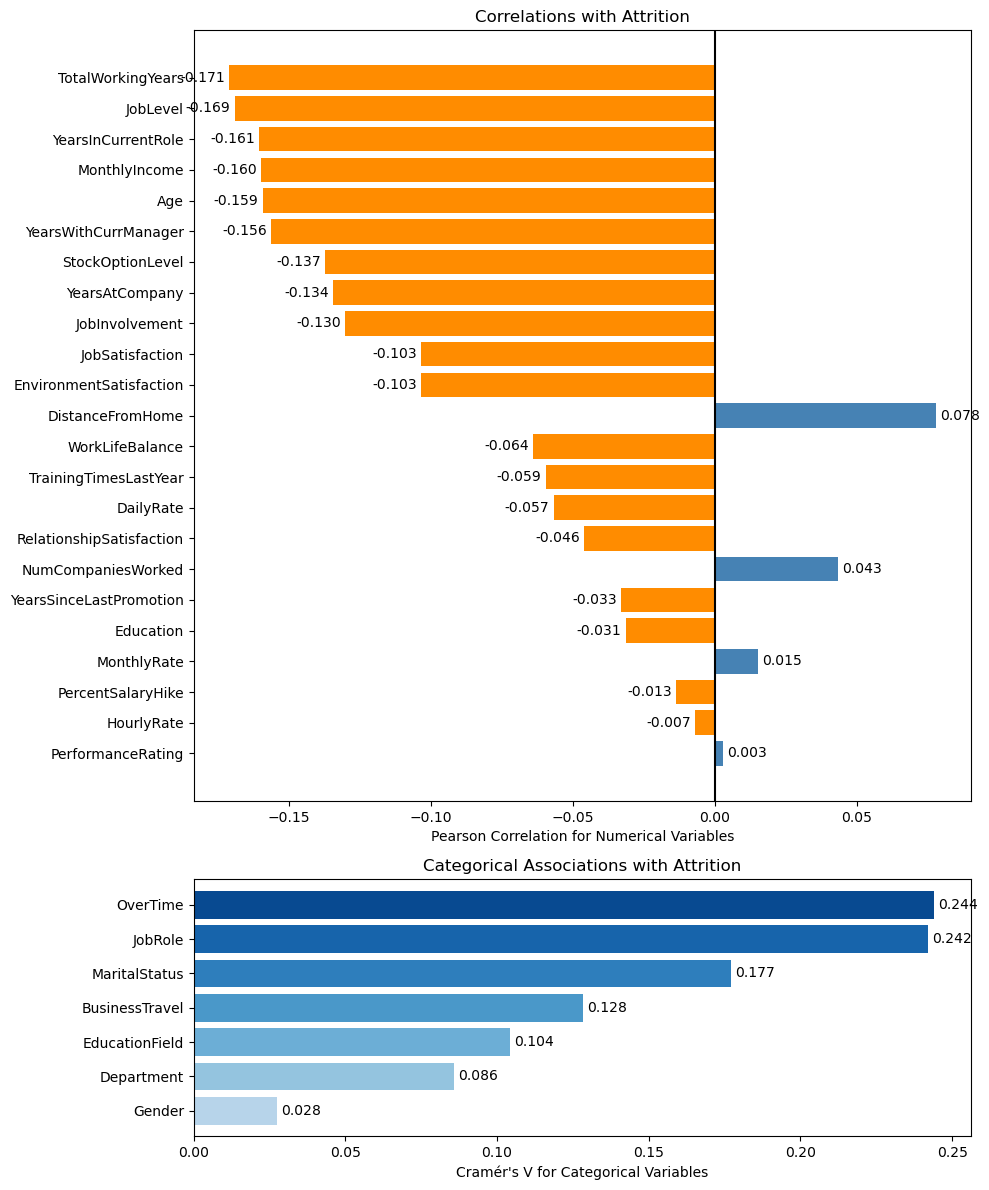

In [12]:
# Visual 1: Showing Attrition with a Two Panel Ranked Association chart (or Correlation/association heatmap) 

# Sorting correlations and associations
num_corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
cat_assoc = pd.Series(results).sort_values(ascending=False)

# Creating two panels 
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12),
    gridspec_kw={'height_ratios': [3, 1]})

# Setting up the numeric panel with titles and colorblind safe hues
colors = ['steelblue' if x > 0 else 'darkorange' for x in num_corr]
bars = ax1.barh(num_corr.index, num_corr, color=colors)

ax1.invert_yaxis()
ax1.axvline(0, color='black')
ax1.set_title('Correlations with Attrition')
ax1.set_xlabel('Pearson Correlation for Numerical Variables')
ax1.bar_label(bars, fmt='%.3f', padding=3)

# Setting up the categorical panel with titles and colorblind safe hues
colors = plt.cm.Blues_r(np.linspace(.1, .7, len(cat_assoc)))
bars = ax2.barh(cat_assoc.index, cat_assoc, color=colors)

ax2.invert_yaxis()
ax2.set_title("Categorical Associations with Attrition")
ax2.set_xlabel("Cramér's V for Categorical Variables")
ax2.bar_label(bars, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

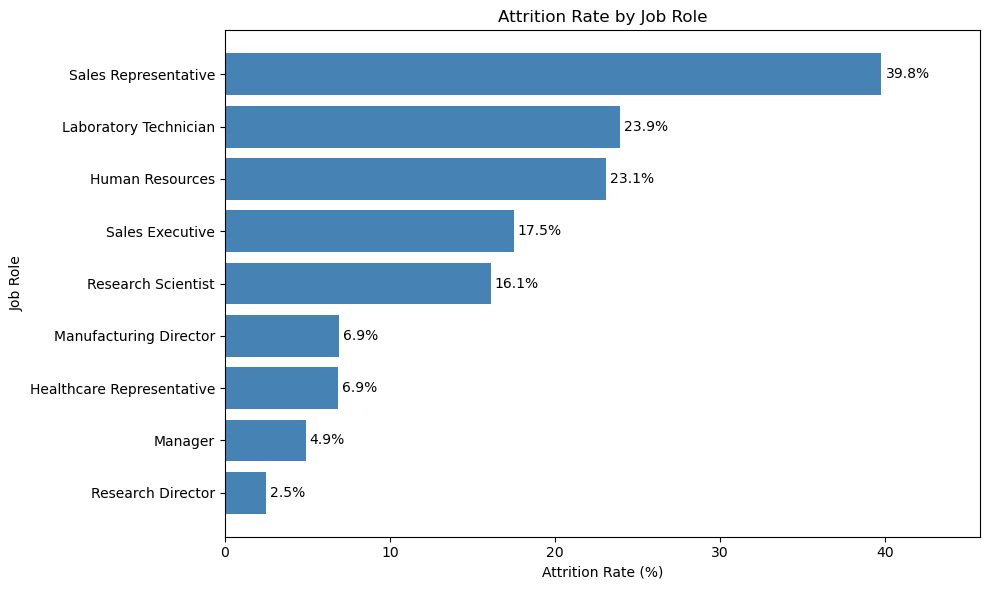

In [13]:
# Visual 2: Bar Chart of Attrition by Job Role

jobrole_attr = (pd.crosstab(df['JobRole'], df['Attrition'], normalize='index')['Yes'] * 100).sort_values()

# Setting up chart dimensions and titles
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(jobrole_attr.index, jobrole_attr.values, color='steelblue')

ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_title('Attrition Rate by Job Role')
ax.set_xlabel('Attrition Rate (%)')
ax.set_ylabel('Job Role')  
ax.set_xlim(0, jobrole_attr.max() * 1.15)

plt.tight_layout()
plt.show()

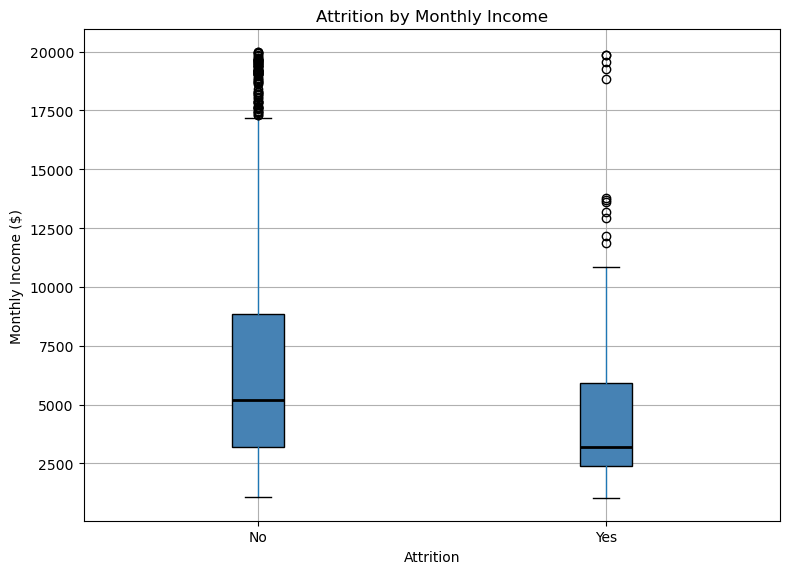

In [14]:
# Visual 3: Box Plot of Attrition by Monthly Income

# Setting the dimensions and titles
fig, ax = plt.subplots(figsize=(8, 6))
df.boxplot(column='MonthlyIncome', by='Attrition', ax=ax, patch_artist=True,
           boxprops=dict(facecolor='steelblue'),
           medianprops=dict(color='black', linewidth=2))

ax.set_title('Attrition by Monthly Income')
plt.suptitle('') # removing the automatic pandas subtitle
ax.set_ylabel('Monthly Income ($)')

plt.tight_layout()
plt.savefig('income_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

**Determinations Before Modeling:**

Heatmap:
* All numeric correlations < |0.2|; OverTime and JobRole are the strongest categorical associations (~0.24)
* The categorical panel reads more clearly because it has fewer variables (7 vs. 23).
* Panels use different measures and aren't directly comparable.

Bar:
* Attrition rates show a big difference across job roles. Sales Representatives have the highest observed attrition rate at 39.8%, while Research Directors have the lowest at 2.5%.
* The range across roles is roughly 16x.
* Sales Representative stands out sharply, far above all other roles with next highest at ~24%. This is a clear priority group for retention efforts.

Box Plot:
* Income alone doesn't separate leavers from stayers.
* Employees who left tend to earn less than employees who stayed. The distribution also shows a wider range of higher incomes among employees who did not leave.
* Median income for employees who left is notably lower than for those who stayed. It reinforces income as a factor to examine in the models.

Overall: <br>
Reinforces what was found in analysis, no single variable strongly predicts attrition. Must use multivariate model.

<br>

## **ENCODE THE DATA FOR MODELING**

In [15]:
# Separating features from Attrition + encode categorical

X = df.drop(columns=['Attrition'])
y = df['Attrition'].map({'No': 0, 'Yes': 1})

cat_cols = X.select_dtypes(exclude='number').columns.tolist()
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

print(X.shape, y.shape)
print(X_encoded.shape)

(1470, 30) (1470,)
(1470, 44)


In [16]:
# Splitting the data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.20,
    random_state=42,
    stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(1176, 44) (294, 44)
(1176,) (294,)


**Note:** 1,176 rows for training, 294 for testing, 44 features each. 80/20 split on 1,470 total rows, preserving the 84/16 class ratio in both.

In [17]:
# Training the model and evaluating it on the test set

# Adding additional libraries
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

# Scaling features to the same standard scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Weighting to compensate for the 84/16 class imbalance
log_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[192  55]
 [ 18  29]]
              precision    recall  f1-score   support

           0       0.91      0.78      0.84       247
           1       0.35      0.62      0.44        47

    accuracy                           0.75       294
   macro avg       0.63      0.70      0.64       294
weighted avg       0.82      0.75      0.78       294



### Comparison Model: Decision Tree

A decision tree was evaluated as an alternative to logistic regression, using the same training and testing split. Decision trees do not require feature scaling, so the unscaled training data is used. The tree depth is limited to 4 to reduce overfitting, and balanced class weights match the logistic regression setup.

In [18]:
# Training a decision tree on the same split for comparison

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score

tree_model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print(confusion_matrix(y_test, y_pred_tree))
print(classification_report(y_test, y_pred_tree))
print(f"Recall for employees who left - Decision Tree: {recall_score(y_test, y_pred_tree):.2f} | Logistic Regression: {recall_score(y_test, y_pred):.2f}")

[[188  59]
 [ 24  23]]
              precision    recall  f1-score   support

           0       0.89      0.76      0.82       247
           1       0.28      0.49      0.36        47

    accuracy                           0.72       294
   macro avg       0.58      0.63      0.59       294
weighted avg       0.79      0.72      0.75       294

Recall for employees who left - Decision Tree: 0.49 | Logistic Regression: 0.62


**Determination: Decision Tree**

* The decision tree did not perform as well. Its recall for employees who left was 0.49, compared with 0.62 for logistic regression. Logistic regression (with scaling and class weighting) performed better for identifying attrition.
* The model identified 62% of employees who actually left, but precision was only 35%, indicating a relatively high number of false positives.
* Attrition is an imbalanced outcome; recall, precision, and F1 are more informative than overall accuracy, showing a tradeoff between identifying more at-risk employees and incorrectly flagging employees who would stay.

### Cross-Validation

To confirm the results are not dependent on a single train/test split, both models were evaluated with 5-fold stratified cross-validation on the training data. Scaling is placed inside a pipeline so it is fit only on each training fold, preventing data leakage.

In [19]:
# Cross-validating both models using 5 folds on the training data

# Adding needed libraries
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

# Setting up 5 folds that keep the 84/16 class ratio in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Putting scaling inside a pipeline so it is only fit on each training fold
log_pipeline = make_pipeline(StandardScaler(),
                             LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))

tree_cv_model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)

# Scoring each model on recall, precision, and average precision
for metric in ['recall', 'precision', 'average_precision']:
    log_scores = cross_val_score(log_pipeline, X_train, y_train, cv=cv, scoring=metric)
    tree_scores = cross_val_score(tree_cv_model, X_train, y_train, cv=cv, scoring=metric)

    print(metric)
    print(f'Logistic Regression: {log_scores.mean():.2f} (+/- {log_scores.std():.2f})')
    print(f'Decision Tree:       {tree_scores.mean():.2f} (+/- {tree_scores.std():.2f})')
    print()

recall
Logistic Regression: 0.74 (+/- 0.06)
Decision Tree:       0.56 (+/- 0.10)

precision
Logistic Regression: 0.37 (+/- 0.03)
Decision Tree:       0.33 (+/- 0.04)

average_precision
Logistic Regression: 0.61 (+/- 0.08)
Decision Tree:       0.34 (+/- 0.04)



**Determination: Cross-Validation**

* Across all five folds, logistic regression outperformed the decision tree on recall (0.74 vs. 0.56), precision (0.37 vs. 0.33), and average precision (0.61 vs. 0.34), confirming the model choice.
* The small variation across folds (about ±0.06 for logistic regression recall) shows the results are stable and not dependent on one particular split.
* Cross-validated recall (0.74) is higher than the single test-set recall (0.62). The test set contains only 294 employees, so one split can vary; the test-set results remain the final reported performance because those employees were never used in training.

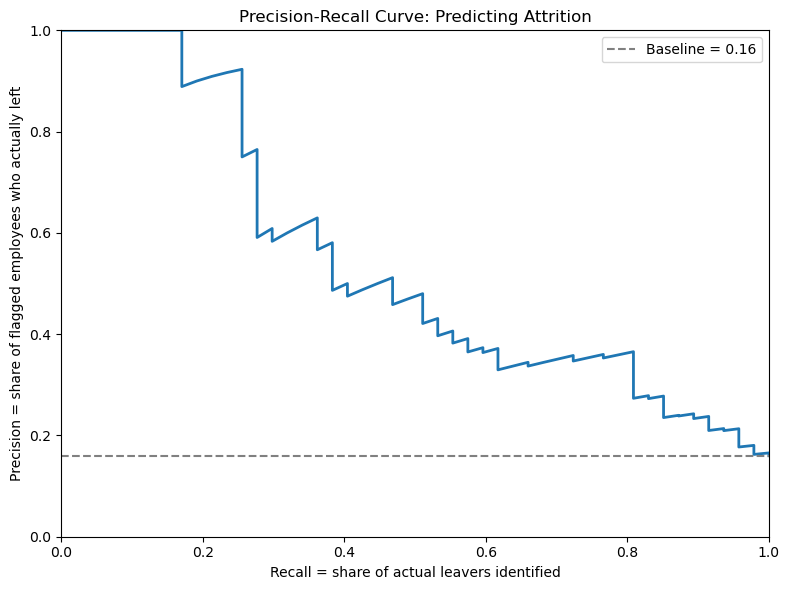

Average Precision: 0.545


In [20]:
# Visual 4: Precision Recall Curve using the trained Logistic Regression Model

# Adding needed library
from sklearn.metrics import precision_recall_curve, average_precision_score

# Getting predicted probabilities for employees who left
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

# Calculating precision and recall
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
avg_precision = average_precision_score(y_test, y_prob)

# Creating the curve
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall, precision, linewidth=2)

# Adding the baseline line
ax.axhline(y=y_test.mean(), color='gray', linestyle='--', label=f'Baseline = {y_test.mean():.2f}')
ax.legend()

ax.set_title('Precision-Recall Curve: Predicting Attrition')
ax.set_xlabel('Recall = share of actual leavers identified')
ax.set_ylabel('Precision = share of flagged employees who actually left')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

print(f'Average Precision: {avg_precision:.3f}')

**Determination After Modeling**

* The curve plots how many actual leavers the model catches (Recall) against how many of its flags are correct (Precision), at every possible classification threshold.
* This visual was the right call because imbalanced classes (84/16) make accuracy less informative; PR curve shows the full picture.
* The baseline of 0.16 reflects the proportion of employees who left. A model with no useful ability to rank attrition risk would have expected precision around this level.
* The model scored 0.545 on Average Precision, meaning it ranks employees by attrition risk substantially better than chance. This indicates useful predictive signal in the model.
* The chart shows a tradeoff: the more leavers the model tries to catch, the more false alarms it creates. Precision drops fast once recall passes about 60-70%.
* It allows HR to pick a threshold to prioritize. They need to decide how many false alarms are worth accepting in exchange for catching more employees who are actually at risk of leaving.

### Validating the Risk Tiers

The proposed risk tiers (High: 0.70 and above, Moderate: 0.50 to 0.69, Low: below 0.50) were applied to the test set to check how many employees in each tier actually left. Because balanced class weighting raises predicted probabilities, the tiers were checked against actual outcomes rather than taken at face value.

In [21]:
# Validating the 0.70 and 0.50 risk tiers on the test set

# Placing each test employee into a risk tier based on predicted probability
tiers = pd.cut(y_prob, bins=[0, 0.50, 0.70, 1.0],
               labels=['Low (<0.50)', 'Moderate (0.50-0.69)', 'High (0.70+)'],
               right=False, include_lowest=True)

tier_table = pd.DataFrame({'Tier': tiers, 'Left': y_test.values, 'Predicted': y_prob})

# Summarizing each tier
summary = tier_table.groupby('Tier', observed=False).agg(
    Employees=('Left', 'size'),
    Actually_Left=('Left', 'sum'),
    Avg_Predicted=('Predicted', 'mean'))

summary['Actual_Rate'] = (summary['Actually_Left'] / summary['Employees']).round(3)
summary['Share_of_Leavers'] = (summary['Actually_Left'] / summary['Actually_Left'].sum()).round(3)

print(summary.round(3))
print()
print(f'Average predicted probability: {y_prob.mean():.2f}')
print(f'Actual attrition rate in test set: {y_test.mean():.2f}')

                      Employees  Actually_Left  Avg_Predicted  Actual_Rate  \
Tier                                                                         
Low (<0.50)                 210             18          0.184        0.086   
Moderate (0.50-0.69)         41              7          0.603        0.171   
High (0.70+)                 43             22          0.844        0.512   

                      Share_of_Leavers  
Tier                                    
Low (<0.50)                      0.383  
Moderate (0.50-0.69)             0.149  
High (0.70+)                     0.468  

Average predicted probability: 0.34
Actual attrition rate in test set: 0.16


**Determination: Risk Tier Validation**

* The tiers rank risk in the right order: 51% of High-risk employees actually left, compared with 17% of Moderate-risk and 9% of Low-risk employees.
* The High tier is the most useful. It flags about 15% of employees (43 of 294) while capturing 47% of everyone who left.
* The predicted probabilities are inflated. High-risk employees averaged a 0.84 predicted probability, but only 51% left, and the average prediction overall (0.34) was about double the actual attrition rate (0.16). This is expected with balanced class weighting.
* The Moderate tier (17%) is barely above the 16% baseline, so it does not identify meaningfully elevated risk in this test set.
* The tiers should be treated as relative rankings of risk, not literal probabilities of leaving. HR should focus individual outreach on the High tier and validate or recalibrate the cutoffs on its own data before use.

### Ethical Evaluation: Subgroup Audit

The model uses age, gender, and marital status as features. To check for potential disparities, model performance on the test set was compared across these groups. Recall shows how many actual leavers in each group were identified, and the flag rate shows how often employees in each group were flagged as at risk.

In [22]:
# Subgroup audit: comparing model results across demographic groups on the test set

from sklearn.metrics import precision_score

# Pulling the original demographic columns for the test employees
audit = df.loc[X_test.index, ['Gender', 'MaritalStatus', 'Age']].copy()
audit['AgeGroup'] = pd.cut(audit['Age'], bins=[17, 29, 39, 49, 60],
                           labels=['Under 30', '30-39', '40-49', '50+'])
audit['Actual'] = y_test.values
audit['Predicted'] = y_pred

# Calculating results for each group
for group in ['Gender', 'AgeGroup', 'MaritalStatus']:
    print(group)
    for name, data in audit.groupby(group, observed=False):
        print(f"  {name}: Employees={len(data)}, Left={data['Actual'].sum()}, "
              f"Attrition Rate={data['Actual'].mean():.2f}, Flag Rate={data['Predicted'].mean():.2f}, "
              f"Recall={recall_score(data['Actual'], data['Predicted'], zero_division=0):.2f}, "
              f"Precision={precision_score(data['Actual'], data['Predicted'], zero_division=0):.2f}")
    print()

Gender
  Female: Employees=116, Left=16, Attrition Rate=0.14, Flag Rate=0.31, Recall=0.69, Precision=0.31
  Male: Employees=178, Left=31, Attrition Rate=0.17, Flag Rate=0.27, Recall=0.58, Precision=0.38

AgeGroup
  Under 30: Employees=68, Left=17, Attrition Rate=0.25, Flag Rate=0.41, Recall=0.76, Precision=0.46
  30-39: Employees=125, Left=14, Attrition Rate=0.11, Flag Rate=0.33, Recall=0.79, Precision=0.27
  40-49: Employees=67, Left=8, Attrition Rate=0.12, Flag Rate=0.15, Recall=0.38, Precision=0.30
  50+: Employees=34, Left=8, Attrition Rate=0.24, Flag Rate=0.15, Recall=0.25, Precision=0.40

MaritalStatus
  Divorced: Employees=64, Left=4, Attrition Rate=0.06, Flag Rate=0.12, Recall=0.75, Precision=0.38
  Married: Employees=133, Left=18, Attrition Rate=0.14, Flag Rate=0.25, Recall=0.56, Precision=0.30
  Single: Employees=97, Left=25, Attrition Rate=0.26, Flag Rate=0.44, Recall=0.64, Precision=0.37



### Safeguard Test: Model Without Sensitive Features

To test a stronger safeguard than restricting access, the logistic regression model was retrained without age, gender, and marital status. If performance holds, these features can be excluded from any real-world use of the model.

In [23]:
# Retraining logistic regression without age, gender, and marital status

from sklearn.metrics import average_precision_score

sensitive = ['Age', 'Gender_Male', 'MaritalStatus_Married', 'MaritalStatus_Single']

X_train_fair = X_train.drop(columns=sensitive)
X_test_fair = X_test.drop(columns=sensitive)

# Scaling and training the same way as the original model
scaler_fair = StandardScaler()
X_train_fair_scaled = scaler_fair.fit_transform(X_train_fair)
X_test_fair_scaled = scaler_fair.transform(X_test_fair)

fair_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
fair_model.fit(X_train_fair_scaled, y_train)

y_pred_fair = fair_model.predict(X_test_fair_scaled)
y_prob_fair = fair_model.predict_proba(X_test_fair_scaled)[:, 1]

# Comparing overall performance
print('With sensitive features:    '
      f'Recall={recall_score(y_test, y_pred):.2f}, Precision={precision_score(y_test, y_pred):.2f}, '
      f'Avg Precision={average_precision_score(y_test, y_prob):.3f}')
print('Without sensitive features: '
      f'Recall={recall_score(y_test, y_pred_fair):.2f}, Precision={precision_score(y_test, y_pred_fair):.2f}, '
      f'Avg Precision={average_precision_score(y_test, y_prob_fair):.3f}')
print()

# Comparing recall by age group for both models
audit['Predicted_Fair'] = y_pred_fair
print('Recall by Age Group (original vs. without sensitive features)')
for name, data in audit.groupby('AgeGroup', observed=False):
    original = recall_score(data['Actual'], data['Predicted'], zero_division=0)
    fair = recall_score(data['Actual'], data['Predicted_Fair'], zero_division=0)
    print(f'  {name}: {original:.2f} vs. {fair:.2f}')

With sensitive features:    Recall=0.62, Precision=0.35, Avg Precision=0.545
Without sensitive features: Recall=0.62, Precision=0.36, Avg Precision=0.527

Recall by Age Group (original vs. without sensitive features)
  Under 30: 0.76 vs. 0.71
  30-39: 0.79 vs. 0.71
  40-49: 0.38 vs. 0.62
  50+: 0.25 vs. 0.25


**Determination: Subgroup Audit and Safeguards**

* Gender: The model performed similarly for women and men (recall 0.69 vs. 0.58), with no major disparity.
* Age: The original model identified most leavers under 40 (recall 0.76-0.79) but missed most older leavers (0.38 for ages 40-49 and 0.25 for 50+). Older employees who leave are largely overlooked.
* Marital status: Single employees were flagged most often (44%), reflecting their higher actual attrition rate (26%) rather than a clear performance gap.
* Removing age, gender, and marital status had almost no effect on overall performance (recall 0.62 for both; average precision 0.527 vs. 0.545) and improved recall for employees aged 40-49 from 0.38 to 0.62.
* Recall for employees 50 and older remained low (0.25) in both models. With only 8 leavers in this group, results should be interpreted with caution, and this group needs particular attention in any real-world use.

**Recommended Safeguards**

* Exclude age, gender, and marital status from any deployed version of the model, since they add little predictive value.
* Repeat this subgroup audit each time the model is retrained, with special attention to older employees.
* Use model results only for supportive retention outreach, never for hiring, promotion, discipline, or termination decisions.
* Require HR review before any action, and give employees the option to decline retention conversations.
* Limit data to what the model needs, restrict access to authorized HR staff, and remove individual risk scores after they are used.
* Review the model with legal and compliance teams before deployment to ensure it meets employment laws and guidelines.

In [24]:
# Logistic Regression Coefficients

coefs = pd.Series(log_model.coef_[0], index=X_encoded.columns).sort_values()
print(coefs.round(3))

TotalWorkingYears                   -0.660
EducationField_Life Sciences        -0.512
YearsWithCurrManager                -0.461
EducationField_Medical              -0.452
EnvironmentSatisfaction             -0.434
JobSatisfaction                     -0.393
EducationField_Other                -0.390
JobRole_Research Director           -0.388
JobInvolvement                      -0.285
Age                                 -0.267
EducationField_Marketing            -0.257
RelationshipSatisfaction            -0.253
PercentSalaryHike                   -0.239
DailyRate                           -0.231
WorkLifeBalance                     -0.229
YearsInCurrentRole                  -0.226
StockOptionLevel                    -0.202
TrainingTimesLastYear               -0.170
EducationField_Technical Degree     -0.128
MonthlyIncome                       -0.097
HourlyRate                          -0.056
JobRole_Manager                      0.003
Education                            0.020
MonthlyRate